# Module 1: Regression

This learning module develops linear regression from the ground up. All code is included after the introductory materials are presented.

### Overview

We will begin by constructing a probabilistic model for our observed data. From this model, we will derive a criterion for estimating the unknown parameters, establish the existence and uniqueness of solutions, and finally study computational methods for obtaining these estimates.

## Problem Formulation

Suppose we have a finite sequence $\mathcal{D} = (\mathbf{x}_n)^N_{n=1}$ with elements in $\mathbb{R}^K$ with $K \in \mathbb{N}$. We will write elements of this sequence as $\mathbf{x}_n = (x_{n,1}, \ldots, x_{n,K})$, $1 \le n \le N$. Thus, we may construct from $\mathcal{D}$, an $N\times K$ real-valued matrix
$$\mathcal{X}:= (x_{n,k})_{1\le n \le N,\, 1\le k \le K}.$$

We may consider $\mathcal{D}$ to be a *dataset* with $N$ fixed *observations* $\mathbf{x}_1, \ldots, \mathbf{x}_N$. These observations are $K$-tuples, where each entry in the tuple corresponds to the value the given observation takes on with respect to the $k$-th *variable of interest*.

Suppose also that we are given a vector $\mathcal{Y} = (\gamma_1, \ldots, \gamma_N) \in \mathbb{R}^N$. We may think of $\mathcal{Y}$ as *labels* corresponding to each observation $(\mathbf{x}_n, \gamma_n)$. That is, we represent the vector $\mathbf{x}_n$ by one scalar $\gamma_n \in \mathbb{R}$. For example, our dataset could consist of variables describing the characteristics of a home for sale (e.g. sq. footage, number of bedrooms, etc.), while the label could simply be the home price.

With respect to the data $(\mathbf{x}_n, \gamma_n)$, we assume that there exists a *data-generating* function $f:\mathbb{R}^K \to \mathbb{R}$, where $f(\mathbf{x}_n)$ is the *true* label with respect to $\mathbf{x}_n$. This function is usually **unknown** to us. In practice, there is typically some form of measurement error with respect to the data. As an example, any data collected from some sort of physical sensor will contain small measurement error. With this in mind, we assume that the label data that we measure, $\mathcal{Y} = (\gamma_1, \ldots, \gamma_N)$, is a *noisy* output of this data-generating function. Many texts write shorthand notation for this concept. To make this more concrete for the first-time reader, first recall that $\mathcal{B}(\mathbb{R})$ is the Borel $\sigma$-algebra on $\mathbb{R}$. Now suppose that $(\Omega, \mathcal{F}, \mathbb{P})$ is a probability space with $\mathcal{F}/\mathcal{B}(\mathbb{R})$-measurable functions (random variables)

$$
\epsilon_1, \ldots, \epsilon_N: \Omega \to \mathbb{R}
$$

such that for $A \in \mathcal{B}(\mathbb{R})$,

$$   
    \mathbb{P}(\epsilon_n^{-1}(A)) = \int_A \frac{1}{\sqrt{2\pi\sigma^2}}\exp\left(-\frac{t^2}{2\sigma^2}\right)\:dt, \quad 1 \le n \le N,
$$

where $\sigma^2 >0$ is known to us. Equivalently, 
$$
    \mathbb{P}\circ \epsilon_n^{-1} = \mathcal{N}(0, \sigma^2), \quad 1 \le n \le N.
$$

Thus, the random variables $\epsilon_n$ are identically distributed. Moreover, let us assume the $\epsilon_n$ are independent; i.e., for $A_1, \ldots, A_N \in \mathcal{B}(\mathbb{R})$,

$$
    \mathbb{P}\left(\bigcap^N_{n=1}\epsilon_n^{-1}(A_n)\right) = \prod^N_{n=1} \mathbb{P}(\epsilon_n^{-1}(A_n)).
$$

Thus, the $\epsilon_n$ are independent and identically distributed (i.i.d.) zero-centered Gaussian noise. Note here that the probability space is entirely abstract. We just need a probability space that supports these $N$ i.i.d. Gaussians. Now define the random variables

$$ Y_n: \Omega \to \mathbb{R}, \quad Y_n(\omega) = f(\mathbf{x}_n) + \epsilon_n(\omega)$$
for each $1 \le n \le N$. Thus,
$$
    Y_n \sim \mathcal{N}(f(\mathbf{x}_n), \sigma^2).
$$

Observe that the $Y_n$ are independent. Indeed, for any Borel set $A \subseteq \mathbb{R}$ and $t \in \mathbb{R}$, it follows that $A +t = \{a+t: a \in A\} \in \mathcal{B}(\mathbb{R})$. In particular, for $A_1, \ldots, A_N \in \mathcal{B}(\mathbb{R})$, we have that

$$
\mathbb{P}\left(\bigcap^N_{n=1}Y_n^{-1}(A_n)\right) = \mathbb{P}\left(\bigcap^N_{n=1}\epsilon_n^{-1}(A_n - f(\mathbf{x}_n))\right) = \prod^N_{n=1} \mathbb{P}(\epsilon_n^{-1}(A_n - f(\mathbf{x}_n))) =  \prod^N_{n=1} \mathbb{P}(Y_n^{-1}(A_n)). 
$$

Define the random vector
$$
    \mathbf{Y}: \Omega \to \mathbb{R}^N, \quad \mathbf{Y}(\omega) = (Y_1(\omega), \ldots, Y_N(\omega)).
$$

We assume that our observed labels are a realization of $\mathbf{Y}$. That is, for some $\omega_0 \in \Omega$, we have

$$
\mathcal{Y} = \mathbf{Y}(\omega_0) = (Y_1(\omega_0), \ldots, Y_N(\omega_0)) = (\gamma_1, \ldots, \gamma_N).
$$

**Our Goal:** Find a function $\widehat{f}: \mathbb{R}^K \to \mathbb{R}$ such that $\widehat{f}$ approximates $f$ "well". Since $f$ is unknown, we cannot directly evaluate the discrepancy between $f$ and $\widehat f$. Instead, we introduce the notion of a *loss function*, which allows us to quantify the discrepancy between our predictions and the noisy observed labels. We will discuss this concept in future sections.

## Linear Regression

We again fix our data and construct a design matrix $\mathcal{X}$ from the data $(\mathbf{x}_n)^N_{n=1}$, $\mathbf{x}_n \in \mathbb{R}^K$ for $1 \le n \le N$, with labels $\mathcal{Y} \in \mathbb{R}^N$ as defined above.

Now that we have discussed the main problem formulation for regression, we restrict our attention to data-generating functions $f:\mathbb{R}^K \to \mathbb{R}$ belonging to the class of affine functions on $\mathbb{R}^K$. In particular, we assume there exists $\mathbf{\theta}_* = (\theta_{*,1}, \ldots, \theta_{*,K}) \in \mathbb{R}^K$ and $b_* \in \mathbb{R}$ such that

$$f(\mathbf{x}) = \langle \mathbf{x}, \mathbf{\theta}_* \rangle_{\mathbb{R}^K} + b_*,$$

where $\langle \cdot, \cdot\rangle_{\mathbb{R}^K}$ is the Euclidean inner-product. This inner product is also referred to as the *dot product*. Here, $\mathbf{\theta}_*$ and $b_*$ are unknown parameters that we wish to estimate. 

To make our lives easier, we may consider the data to be of the form $\tilde{\mathbf{x}}_n:= (1, x_{n,1}, \ldots, x_{n,K})$. Appending $1$ to the original tuples allows us to remove the $b_*$ term in the formulation above. Indeed, consider the vector $\tilde{\mathbf{\theta}}_*:= (b_*, \theta_{*,1}, \ldots, \theta_{*,K}) \in \mathbb{R}^{K+1}$. Then we define $\tilde{f}:\mathbb{R}^{K+1} \to \mathbb{R}$ as

$$\tilde{f}(\mathbf{x}) = \langle \mathbf{x},\tilde{\mathbf{\theta}}_* \rangle_{\mathbb{R}^{K+1}}.$$

This gives

$$
    f(\mathbf{x}_n) = \langle \mathbf{x}_n, \mathbf{\theta}_* \rangle_{\mathbb{R}^K} + b_* = \langle \tilde{\mathbf{x}}_n, \tilde{\mathbf{\theta}}_* \rangle_{\mathbb{R}^{K+1}} = \tilde{f}(\tilde{\mathbf{x}}_n)
$$
for each $1 \le n \le N$. Define

$$
    \iota: \mathbb{R}^{K} \to \mathbb{R}^{K+1}, \quad \iota(\mathbf{x}) = (1, \mathbf{x}).
$$

Then it is clear that $f = \tilde{f} \circ \iota$, and thus, the augmented formulation agrees with the original function on every input under the natural identification. To ease notation, we will no longer write the tilde symbol above the data and the function $f$ and relabel the dimension $K+1$ to $K$. 


We see that $f \in (\mathbb{R}^{K})^*$, the dual of $\mathbb{R}^{K}$, and so the problem then becomes: find a linear functional in the dual of $\mathbb{R}^{K}$ that approximates the data-generating function $f$.

Towards this end, we observe that by the independence of the $Y_1, \ldots, Y_N$, the joint density of $\mathbf{Y}$ evaluated at $\mathcal{Y}$ is given by

$$
p(\mathcal{Y}| \mathcal{X}, \mathbf{\theta}_* ) = \prod^N_{n=1} p(\gamma_n| \mathbf{x}_n, \mathbf{\theta}_*) = \prod^N_{n=1}\mathcal{N}(\gamma_n|\langle \mathbf{x}_n, \mathbf{\theta}_* \rangle_{\mathbb{R}^K}, \sigma^2) = \prod^N_{n=1} \frac{1}{\sqrt{2\pi\sigma^2}}\exp\left(-\frac{(\gamma_n-\langle \mathbf{x}_n, \mathbf{\theta}_*\rangle_{\mathbb{R}^K})^2}{2\sigma^2}\right).
$$ 

Here, $p$ is the density function and **not** a probability. Since $\mathbf{\theta}_*$ is unknown to us, we would like to find some parameter $\mathbf{\theta} \in \mathbb{R}^K$ that gives us a good approximation to $f$. For each candidate parameter, we generate a new probability density $p(\cdot | \mathcal{X}, \mathbf{\theta})$. Fixing our observed labels $\mathcal{Y}$, we define the likelihood function

$$
    \mathcal{L}: \mathbb{R}^K \to (0, \infty), \quad \mathcal{L}(\mathbf{\theta}) = p(\mathcal{Y}| \mathcal{X}, \mathbf{\theta}) := \prod^N_{n=1} \frac{1}{\sqrt{2\pi\sigma^2}}\exp\left(-\frac{(\gamma_n-\langle \mathbf{x}_n, \mathbf{\theta}\rangle_{\mathbb{R}^K})^2}{2\sigma^2}\right).
$$

### Properties of the Likelihood Function

At this point, most machine learning textbooks will now maximize the likelihood function we have defined above, often with little to no justification. Let us rigorously study this function and investigate the mathematical motivation for maximizing the likelihood when estimating our unknown data-generating function $f$.

We first build some intuition and define some objects that will make this process work. Let $\mathbf{\theta} \in \mathbb{R}^K$. Similarly to how we have done before, let us define the random variables

$$
    Y_n^\mathbf{\theta}: \Omega \to \mathbb{R}, \quad Y_n^{\mathbf{\theta}}(\omega) = \langle \mathbf{x}_n, \mathbf{\theta} \rangle_{\mathbb{R}^K} + \epsilon_n(\omega), \quad 1 \le n \le N.
$$

Thus,

$$
    Y_n^{\mathbf{\theta}} \sim \mathcal{N}(\langle \mathbf{x}_n, \mathbf{\theta} \rangle_{\mathbb{R}^K}, \sigma^2).
$$

Also define the random vector

$$
    \mathbf{Y}^\mathbf{\theta}: \Omega \to \mathbb{R}^N, \quad \mathbf{Y}^{\mathbf{\theta}}(\omega) = (Y_1^{\mathbf{\theta}}(\omega), \ldots, Y_N^{\mathbf{\theta}}(\omega)).
$$

Let us make a couple of observations about these random variables. Taking $\mathbf{\theta} = \mathbf{\theta}_*$ gives $\mathbf{Y}^{\mathbf{\theta}} = \mathbf{Y}$, as defined in the previous section. Moreover, for $\mathbf{y} = \mathcal{Y}$, the joint density of $\mathbf{Y}^{\mathbf{\theta}}$ evaluated at $\mathcal{Y}$ is given by

$$
    p(\mathcal{Y} | \mathcal{X}, \mathbf{\theta}) = \mathcal{L}(\mathbf{\theta}).
$$

Suppose $\mathbf{\theta}_1$ and $\mathbf{\theta}_2$ are two candidate parameters to construct our approximate data-generating function such that

$$
    \mathcal{L}(\mathbf{\theta}_1) = p(\mathcal{Y}| \mathcal{X}, \mathbf{\theta}_1) > p(\mathcal{Y}| \mathcal{X}, \mathbf{\theta}_2) = \mathcal{L}(\mathbf{\theta}_2)
$$

Because these Gaussian densities are continuous functions, for $\delta > 0$ small enough, we see that

$$
    \begin{align*}
    \mathbb{P}_{\mathbf{\theta}_1}(B_{\delta}(\mathcal{Y}))= \mathbb{P}(\{\omega \in \Omega: \mathbf{Y}^{\mathbf{\theta}_1}(\omega) \in B_\delta(\mathcal{Y})\}) &= \int_{B_\delta(\mathcal{Y})} p(\mathbf{y}| \mathcal{X}, \mathbf{\theta}_1) \, d\mathbf{y}\\
     &> \int_{B_\delta(\mathcal{Y})} p(\mathbf{y}| \mathcal{X}, \mathbf{\theta}_2) \, d\mathbf{y}\\
    &=  \mathbb{P}(\{\omega \in \Omega: \mathbf{Y}^{\mathbf{\theta}_2}(\omega) \in B_\delta(\mathcal{Y})\})\\
    &=\mathbb{P}_{\mathbf{\theta}_2}(B_\delta(\mathcal{Y})),
    \end{align*}
$$

where 
$$
\mathbb{P}_{\mathbf{\theta}_i} = \mathbb{P} \circ (\mathbf{Y}^{\mathbf{\theta}_i})^{-1}, \quad i = 1,2,
$$

and $B_\delta(\mathcal{Y})$ is the open ball of radius $\delta$ centered at $\mathcal{Y}$. So, choosing $\mathbf{\theta}_1$ over $\mathbf{\theta}_2$ yields a higher probability of observing an output $\mathbf{y}$ from our approximate data-generating function that lies $\delta$-close to the data labels $\mathcal{Y}$. Thus, the most natural course of action would be to maximize the likelihood function $\mathcal{L}(\cdot)$. 

We now provide a further mathematical justification for maximizing the likelihood function.

$$
    \mathcal{L}:\mathbb{R}^K \times \mathbb{R}^N \to (0, \infty), \quad \mathcal{L}(\mathbf{\theta}, \mathbf{y}) = p(\mathbf{y} | \mathcal{X}, \mathbf{\theta}).
$$

A quick observation is that if we fix $\mathbf{y} = \mathcal{Y}$, we will get back our likelihood function $\mathcal{L}(\mathbf{\theta})$. Now fix $\mathbf{\theta} \in \mathbb{R}^K$ and define the random variable

$$
    \mathcal{L}(\mathbf{\theta}, \mathbf{Y}): \Omega \to (0, \infty), \quad \mathcal{L}(\mathbf{\theta}, \mathbf{Y})(\omega) := \mathcal{L}(\mathbf{\theta}, \mathbf{Y}(\omega))= p(\mathbf{Y}(\omega)| \mathcal{X}, \mathbf{\theta}),
$$

where $\mathbf{Y}$ is the random variable associated with our label data. To see that $\mathcal{L}(\mathbf{\theta}, \mathbf{Y})$ is indeed a random variable, define the function

$$
    g_\mathbf{\theta}: \mathbb{R}^N \to \mathbb{R}, \quad g_\mathbf{\theta}(\mathbf{y}) = \mathcal{L}(\mathbf{\theta}, \mathbf{y}) = p(\mathbf{y} | \mathcal{X}, \mathbf{\theta}).
$$
Since the Gaussian densities are continuous, we see that $g_{\mathbf{\theta}}$ is continuous and hence Borel measurable. Lastly, observe that for $A \in \mathcal{B}(\mathbb{R})$, we have that

$$ \mathcal{L}(\mathbf{\theta}, \mathbf{Y}) = (g_\mathbf{\theta} \circ \mathbf{Y})\implies \mathcal{L}(\mathbf{\theta}, \mathbf{Y})^{-1}(A) = (g_\mathbf{\theta} \circ \mathbf{Y})^{-1}(A) = \mathbf{Y}^{-1}(g_{\mathbf{\theta}}^{-1}(A)) \in \mathcal{F}$$

as required.

Since $g_{\mathbf{\theta}}$ is Borel measurable, we compute the expectation to be

$$
    \mathbb{E}[\mathcal{L}(\mathbf{\theta},\mathbf{Y})] =  \mathbb{E}[g_{\mathbf{\theta}}\circ \mathbf{Y}]=  \int_{\mathbb{R}^N} g_\mathbf{\theta}(\mathbf{y})p(\mathbf{y}|\mathcal{X}, \mathbf{\theta}_*) \:d\mathbf{y} = \int_{\mathbb{R}^N} p(\mathbf{y} | \mathcal{X}, \mathbf{\theta})p(\mathbf{y}|\mathcal{X}, \mathbf{\theta}_*) \:d\mathbf{y}.
$$

We have the following proposition.

**Proposition.** *Let* $\mathbf{\theta} \in \mathbb{R}^K$. *Then*

$$
    \mathbb{E}[\mathcal{L}(\mathbf{\theta}, \mathbf{Y})] \le \mathbb{E}[\mathcal{L}(\mathbf{\theta}_*, \mathbf{Y})].
$$
*Moreover, we obtain equality if and only if*

$$
    \mathbf{\theta}_* - \mathbf{\theta} \in \text{Ker}(\mathcal{X}),
$$
*where* $\mathcal{X}$ *is the design matrix. In particular,* $\mathbf{\theta}_*$ *is the unique maximizer of the expected likelihood if and only if* $\mathcal{X}$ *has full column rank.*


**Remark.** The above proposition establishes that the expected likelihood is maximized by the true parameter $\mathbf{\theta}_*$, with uniqueness whenever $\mathcal{X}$ has full column rank. This provides a mathematical motivation for maximizing the likelihood function when estimating our unknown data-generating function. However, this is a statement about the expected likelihood over possible realizations of our data, and does not guarantee that maximizing the likelihood associated with a particular realization will produce an accurate approximation of $\mathbf{\theta}_*$. We will investigate the statistical properties of such estimators subsequently.

*Proof.* Recall that

$$
\begin{align*}
    p(\mathcal{Y} | \mathcal{X}, \mathbf{\theta}_*) &= \prod^N_{n=1} \frac{1}{\sqrt{2\pi\sigma^2}} \exp\left( -\frac{(\gamma_n - \langle \mathbf{x}_n, \mathbf{\theta}_*\rangle_{\mathbb{R}^K})^2}{2\sigma^2}\right)\\
    & = (2\pi\sigma^2)^{-N/2}\exp\left(-\frac{1}{2\sigma^2} \sum^N_{n=1}(\gamma_n - \langle \mathbf{x}_n, \mathbf{\theta}_*\rangle_{\mathbb{R}^K})^2\right)\\
    & = (2\pi\sigma^2)^{-N/2}\exp\left(-\frac{||\mathcal{Y} - \mathcal{X}\mathbf{\theta}_*||^2_{\mathbb{R}^N}}{2\sigma^2}\right).
\end{align*}
$$

Let $\mathbf{\theta} \in \mathbb{R}^K$. Then

$$
    p(\mathbf{y} | \mathcal{X}, \mathbf{\theta}) = (2\pi\sigma^2)^{-N/2}\exp\left(-\frac{||\mathbf{y} - \mathcal{X}\mathbf{\theta}||^2_{\mathbb{R}^N}}{2\sigma^2}\right).
$$

But then

$$ 
\begin{align*}
p(\mathbf{y}-\mathcal{X}(\mathbf{\theta}-\mathbf{\theta}_*)\mid\mathcal{X},\mathbf{\theta}_*)&=(2\pi\sigma^2)^{-N/2}\exp\left(
-\frac{\|\mathbf{y}-\mathcal{X}(\mathbf{\theta}-\mathbf{\theta}_*)-\mathcal{X}\mathbf{\theta}_*\|_{\mathbb{R}^N}^2}{2\sigma^2}
\right)\\
& =(2\pi\sigma^2)^{-N/2}\exp\left(
-\frac{\|\mathbf{y}-\mathcal{X}\mathbf{\theta}\|_{\mathbb{R}^N}^2}{2\sigma^2}
\right)\\
 &=p(\mathbf{y}\mid\mathcal{X},\mathbf{\theta}).
\end{align*}
$$

So these densities are merely translations of each other. Observe that the Gaussian densities belong to $L^2(\mathbb{R}^N)$. Indeed, the exponential function is increasing so that

$$
\begin{align*}
 -\frac{|| \mathbf{y} - \mathcal{X}\mathbf{\theta} ||^2_{\mathbb{R}^N}}{2\sigma^2}  \le 0 &\implies \exp\left(-\frac{|| \mathbf{y} - \mathcal{X}\mathbf{\theta} ||^2_{\mathbb{R}^N}}{2\sigma^2}\right) \le e^0= 1\\
  &\implies p(\mathbf{y} | \mathcal{X}, \mathbf{\theta}) \le (2\pi\sigma^2)^{{-N/2}}\\
  & \implies \int_{\mathbb{R}^N} p(\mathbf{y} | \mathcal{X}, \mathbf{\theta})^2 \, d\mathbf{y} \le (2\pi\sigma^2)^{{-N/2}}\int_{\mathbb{R}^N} p(\mathbf{y} | \mathcal{X}, \mathbf{\theta}) \, d\mathbf{y} = (2\pi\sigma^2)^{{-N/2}} < \infty,
 \end{align*}
$$

for $\mathbf{y} \in \mathbb{R}^N$ and $\mathbf{\theta} \in \mathbb{R}^K$. Translation invariance of the Lebesgue measure then gives 

$$
    || p(\cdot | \mathcal{X}, \mathbf{\theta}) ||_{L^2(\mathbb{R}^N)} = || p(\cdot | \mathcal{X}, \mathbf{\theta}_*) ||_{L^2(\mathbb{R}^N)}.
$$

By Cauchy-Schwarz, it follows that

$$
    \mathbb{E}[\mathcal{L}(\mathbf{\theta}, \mathbf{Y})] = \int_{\mathbb{R}^N} p(\mathbf{y}|\mathcal{X}, \mathbf{\theta})p(\mathbf{y}|\mathcal{X}, \mathbf{\theta}_*)\, d\mathbf{y} \le || p(\cdot | \mathcal{X}, \mathbf{\theta}) ||_{L^2(\mathbb{R}^N)} || p(\cdot | \mathcal{X}, \mathbf{\theta}_*) ||_{L^2(\mathbb{R}^N)} = || p(\cdot | \mathcal{X}, \mathbf{\theta}_*) ||^2_{L^2(\mathbb{R}^N)} = \mathbb{E}[\mathcal{L}(\mathbf{\theta}_*, \mathbf{Y})].
$$

This takes care of the inequality case.

If we achieve equality, the equality case of Cauchy-Schwarz tells us that 

$$
    p(\cdot | \mathcal{X}, \mathbf{\theta}_*)= \alpha p(\cdot | \mathcal{X}, \mathbf{\theta}) \quad \text{a.e.}
$$

for some $\alpha \in \mathbb{R}$. But then, integrating the densities shows that

$$
    \alpha = \alpha\int_{\mathbb{R}^N} p(\mathbf{y} | \mathcal{X}, \mathbf{\theta}) \, d\mathbf{y} = \int_{\mathbb{R}^N} \alpha p(\mathbf{y} | \mathcal{X}, \mathbf{\theta})d\mathbf{y} = \int_{\mathbb{R}^N} p(\mathbf{y} | \mathcal{X}, \mathbf{\theta}_*)d\mathbf{y} = 1.
$$

Thus, since densities are continuous and equal almost everywhere, we get density equality everywhere

$$
    p(\cdot | \mathcal{X}, \mathbf{\theta}_*) =  p(\cdot | \mathcal{X}, \mathbf{\theta}).
$$

Because these densities have the same covariance matrix; namely, $\sigma^2I_N$, where $I_N = \text{id}_{\mathbb{R}^N}$, their means must be the same. That is, we must have

$$
    \mathcal{X}\mathbf{\theta}_* - \mathcal{X}\mathbf{\theta} = \mathbf{0} \implies \mathbf{\theta}_* - \mathbf{\theta} \in \text{Ker}(\mathcal{X}),
$$

as required. Conversely, if $\mathbf{\theta}_* - \mathbf{\theta} \in \text{Ker}(\mathcal{X})$, then clearly the densities coincide, and thus, we will get equality of expectation. $\blacksquare$


**Remark.** The proof of the proposition gives a nice functional-analytic interpretation of the densities. Observe that we have

$$
    \begin{align*}
    ||p(\cdot| \mathcal{X}, \mathbf{\theta}) - p(\cdot | \mathcal{X}, \mathbf{\theta}_*)||^2_{L^2(\mathbb{R}^N)} &= \langle p(\cdot| \mathcal{X}, \mathbf{\theta}) - p(\cdot | \mathcal{X}, \mathbf{\theta}_*),  p(\cdot| \mathcal{X}, \mathbf{\theta}) - p(\cdot | \mathcal{X}, \mathbf{\theta}_*)\rangle_{L^2(\mathbb{R}^N)}\\
    &= ||p(\cdot| \mathcal{X}, \mathbf{\theta})||^2_{L^2(\mathbb{R}^N)} -2\langle p(\cdot| \mathcal{X}, \mathbf{\theta}), p(\cdot| \mathcal{X}, \mathbf{\theta}_*)\rangle + ||p(\cdot| \mathcal{X}, \mathbf{\theta}_*)||^2_{L^2(\mathbb{R}^N)}\\
    &= 2||p(\cdot| \mathcal{X}, \mathbf{\theta}_*)||^2_{L^2(\mathbb{R}^N)} -2\langle p(\cdot| \mathcal{X}, \mathbf{\theta}), p(\cdot| \mathcal{X}, \mathbf{\theta}_*)\rangle \\
    &=  2\mathbb{E}[\mathcal{L}(\mathbf{\theta}_*, \mathbf{Y})] - 2\mathbb{E}[\mathcal{L}(\mathbf{\theta}, \mathbf{Y})],
    \end{align*}
$$

for $\mathbf{\theta} \in \mathbb{R}^K$. Thus, we have

$$
    \frac{1}{2}||p(\cdot| \mathcal{X}, \mathbf{\theta}) - p(\cdot | \mathcal{X}, \mathbf{\theta}_*)||^2_{L^2(\mathbb{R}^N)}=\mathbb{E}[\mathcal{L}(\mathbf{\theta}_*, \mathbf{Y})] - \mathbb{E}[\mathcal{L}(\mathbf{\theta}, \mathbf{Y})]
$$

for $\mathbf{\theta} \in \mathbb{R}^K$.

### The Log-Likelihood Function

Recall that for $\mathbf{\theta} \in \mathbb{R}^K$ and $\mathbf{y} \in \mathbb{R}^N$, we have defined

$$
\mathcal{L}(\mathbf{\theta}, \mathbf{y}) = p(\mathbf{y} \mid \mathcal{X}, \mathbf{\theta}).
$$

Since our Gaussian densities are strictly positive, we may consider the function

$$
\log \mathcal{L}: \mathbb{R}^K \times \mathbb{R}^N \to \mathbb{R},
$$

defined by

$$
\log \mathcal{L}(\mathbf{\theta}, \mathbf{y}) = \log\left(\mathcal{L}(\mathbf{\theta}, \mathbf{y})\right).
$$

We call this function the *log-likelihood function*. Recall that the logarithm is strictly increasing on $(0,\infty)$. Consequently, for fixed $\mathbf{y} \in \mathbb{R}^N$ and any $\mathbf{\theta}_1, \mathbf{\theta}_2 \in \mathbb{R}^K$, we have

$$
\mathcal{L}(\mathbf{\theta}_1, \mathbf{y}) \le \mathcal{L}(\mathbf{\theta}_2, \mathbf{y})
\iff
\log \mathcal{L}(\mathbf{\theta}_1, \mathbf{y}) \le \log \mathcal{L}(\mathbf{\theta}_2, \mathbf{y}).
$$

It follows that

$$
\operatorname*{argmax}_{\mathbf{\theta} \in \mathbb{R}^K}
\mathcal{L}(\mathbf{\theta}, \mathcal{Y})
=
\operatorname*{argmax}_{\mathbf{\theta} \in \mathbb{R}^K}
\log \mathcal{L}(\mathbf{\theta}, \mathcal{Y}).
$$

Thus, taking the logarithm does not change our path towards maximization. Moreover, since

$$
\mathcal{L}(\mathbf{\theta}, \mathbf{y})
=
\prod_{n=1}^N
\frac{1}{\sqrt{2\pi\sigma^2}}
\exp\left(
-\frac{(y_n-\langle \mathbf{x}_n,\mathbf{\theta}\rangle_{\mathbb{R}^K})^2}{2\sigma^2}
\right),
$$

we obtain

$$
\log \mathcal{L}(\mathbf{\theta}, \mathbf{y})
=
-\frac{N}{2}\log(2\pi\sigma^2)
-
\frac{1}{2\sigma^2}
\sum_{n=1}^N
(y_n-\langle \mathbf{x}_n,\mathbf{\theta}\rangle_{\mathbb{R}^K})^2.
$$

This expression is substantially easier to work with than the original product of Gaussian densities. Now recall that we have already established that

$$
\mathbb{E}[\mathcal{L}(\mathbf{\theta}, \mathbf{Y})]
\le
\mathbb{E}[\mathcal{L}(\mathbf{\theta}_*, \mathbf{Y})].
$$

A natural question is whether the same relationship holds for the expected log-likelihood:

$$
\mathbb{E}[\log \mathcal{L}(\mathbf{\theta}, \mathbf{Y})]
\le
\mathbb{E}[\log \mathcal{L}(\mathbf{\theta}_*, \mathbf{Y})].
$$

The answer is positive.


**Proposition.** *Let* $\mathbf{\theta} \in \mathbb{R}^K$. *Then*

$$
\mathbb{E}[\log \mathcal{L}(\mathbf{\theta}_*, \mathbf{Y})] - \mathbb{E}[\log \mathcal{L}(\mathbf{\theta}, \mathbf{Y})] = \frac{\|\mathcal{X}(\mathbf{\theta}-\mathbf{\theta}_*)\|_{\mathbb{R}^N}^2}{2\sigma^2}.
$$

*In particular,*

$$
\mathbb{E}[\log \mathcal{L}(\mathbf{\theta}, \mathbf{Y})] \leq \mathbb{E}[\log \mathcal{L}(\mathbf{\theta}_*, \mathbf{Y})],
$$

*with equality if and only if* $\mathbf{\theta}-\mathbf{\theta}_* \in \text{Ker}(\mathcal{X})$.

**Proof.** Fix $\mathbf{\theta} \in \mathbb{R}^K$. Recall that

$$
\log \mathcal{L}(\mathbf{\theta}, \mathbf{Y}) = -\frac{N}{2}\log(2\pi\sigma^2) - \frac{\|\mathbf{Y}-\mathcal{X}\mathbf{\theta}\|_{\mathbb{R}^N}^2}{2\sigma^2}.
$$

Since

$$
\mathbf{Y} = \mathcal{X}\mathbf{\theta}_* + \mathbf{\epsilon},
$$

we have

$$
\mathbf{Y}-\mathcal{X}\mathbf{\theta} = \mathbf{\epsilon}-\mathcal{X}(\mathbf{\theta}-\mathbf{\theta}_*).
$$

Consequently, subtracting the log-likelihoods gives

$$
\log \mathcal{L}(\mathbf{\theta}_*, \mathbf{Y}) - \log \mathcal{L}(\mathbf{\theta}, \mathbf{Y}) = \frac{1}{2\sigma^2}\left(\|\mathbf{\epsilon}-\mathcal{X}(\mathbf{\theta}-\mathbf{\theta}_*)\|_{\mathbb{R}^N}^2 - \|\mathbf{\epsilon}\|_{\mathbb{R}^N}^2\right).
$$

Expanding the squared norm, we obtain

$$
\log \mathcal{L}(\mathbf{\theta}_*, \mathbf{Y}) - \log \mathcal{L}(\mathbf{\theta}, \mathbf{Y}) = \frac{1}{2\sigma^2}\left(\|\mathcal{X}(\mathbf{\theta}-\mathbf{\theta}_*)\|_{\mathbb{R}^N}^2 - 2\langle \mathbf{\epsilon},\mathcal{X}(\mathbf{\theta}-\mathbf{\theta}_*)\rangle_{\mathbb{R}^N}\right).
$$

Taking expectations, we obtain

$$
\mathbb{E}[\log \mathcal{L}(\mathbf{\theta}_*, \mathbf{Y})] - \mathbb{E}[\log \mathcal{L}(\mathbf{\theta}, \mathbf{Y})] = \frac{1}{2\sigma^2}\left(\|\mathcal{X}(\mathbf{\theta}-\mathbf{\theta}_*)\|_{\mathbb{R}^N}^2 - 2\mathbb{E}[\langle \mathbf{\epsilon},\mathcal{X}(\mathbf{\theta}-\mathbf{\theta}_*)\rangle_{\mathbb{R}^N}]\right).
$$

Now observe that

$$
\mathbb{E}[\langle \mathbf{\epsilon},\mathcal{X}(\mathbf{\theta}-\mathbf{\theta}_*)\rangle_{\mathbb{R}^N}] = \langle \mathbb{E}[\mathbf{\epsilon}],\mathcal{X}(\mathbf{\theta}-\mathbf{\theta}_*)\rangle_{\mathbb{R}^N} = 0,
$$

since $\mathbb{E}[\mathbf{\epsilon}]=\mathbf{0}$. Therefore,

$$
\mathbb{E}[\log \mathcal{L}(\mathbf{\theta}_*, \mathbf{Y})] - \mathbb{E}[\log \mathcal{L}(\mathbf{\theta}, \mathbf{Y})] = \frac{\|\mathcal{X}(\mathbf{\theta}-\mathbf{\theta}_*)\|_{\mathbb{R}^N}^2}{2\sigma^2} \geq 0.
$$

Hence,

$$
\mathbb{E}[\log \mathcal{L}(\mathbf{\theta}, \mathbf{Y})] \leq \mathbb{E}[\log \mathcal{L}(\mathbf{\theta}_*, \mathbf{Y})].
$$

Moreover, equality holds if and only if

$$
\mathbf{\theta}-\mathbf{\theta}_* \in \text{Ker}(\mathcal{X}),
$$

as required. $\blacksquare$




### Maximum Likelihood Estimation

We have now established that the true parameter $\mathbf{\theta}_*$ maximizes both the expected likelihood and the expected log-likelihood. However, recall that our objective is to approximate the unknown data-generating function $f$ using only our observed data $\mathcal{Y}$. Since $\mathbf{\theta}_*$ is unknown, we cannot directly maximize the expected likelihood, as its expectation is taken with respect to the distribution determined by $\mathbf{\theta}_*$.

Instead, we maximize the likelihood evaluated at our observed labels $\mathcal{Y}$. A parameter $\widehat{\mathbf{\theta}} \in \mathbb{R}^K$ is called a *maximum likelihood estimate* if

$$
\mathcal{L}(\widehat{\mathbf{\theta}}) = \mathcal{L}(\widehat{\mathbf{\theta}}, \mathcal{Y}) = \sup_{\mathbf{\theta} \in \mathbb{R}^K} \mathcal{L}(\mathbf{\theta}, \mathcal{Y}) = \sup_{\mathbf{\theta} \in \mathbb{R}^K} \mathcal{L}(\mathbf{\theta})
$$

The method of finding such a parameter is called *maximum likelihood estimation (MLE)*. To remind ourselves we are fixing the realization $\mathcal{Y}$, we will use the notation $\mathcal{L}(\mathbf{\theta}, \mathcal{Y})$ for the likelihood function.

At this point, we have not established whether such a parameter exists or whether it is unique. We will now investigate these questions. Recall that the logarithm is strictly increasing, and thus, the maximizers of the likelihood and log-likelihood coincide. Consequently,

$$
\operatorname*{argmax}_{\mathbf{\theta} \in \mathbb{R}^K} \mathcal{L}(\mathbf{\theta}, \mathcal{Y}) = \operatorname*{argmax}_{\mathbf{\theta} \in \mathbb{R}^K}\log \mathcal{L}(\mathbf{\theta}, \mathcal{Y}).
$$

Moreover, we have shown that

$$
\log \mathcal{L}(\mathbf{\theta}, \mathcal{Y}) = -\frac{N}{2}\log(2\pi\sigma^2) - \frac{1}{2\sigma^2}\|\mathcal{Y}-\mathcal{X}\mathbf{\theta}\|_{\mathbb{R}^N}^2.
$$

Since $\sigma^2 > 0$ and the term $-\frac{N}{2}\log(2\pi\sigma^2)$ is independent of $\mathbf{\theta}$, maximizing the log-likelihood is equivalent to minimizing the squared norm appearing in the second term. Thus,

$$
\operatorname*{argmax}_{\mathbf{\theta} \in \mathbb{R}^K} \mathcal{L}(\mathbf{\theta}, \mathcal{Y}) = \operatorname*{argmin}_{\mathbf{\theta} \in \mathbb{R}^K} \|\mathcal{Y}-\mathcal{X}\mathbf{\theta}\|_{\mathbb{R}^N}^2.
$$

Equivalently, we seek a parameter $\widehat{\mathbf{\theta}} \in \mathbb{R}^K$ satisfying

$$
\|\mathcal{Y}-\mathcal{X}\widehat{\mathbf{\theta}}\|_{\mathbb{R}^N}^2 = \inf_{\mathbf{\theta} \in \mathbb{R}^K} \|\mathcal{Y}-\mathcal{X}\mathbf{\theta}\|_{\mathbb{R}^N}^2.
$$

This optimization problem is known as the **ordinary least-squares problem**. This leads us to the following remark.


**Remark.** Recall that our true data-generating function is given by

$$
f(\mathbf{x}) = \langle \mathbf{x}, \mathbf{\theta}_* \rangle_{\mathbb{R}^K}.
$$

For a candidate parameter $\mathbf{\theta} \in \mathbb{R}^K$, define the linear functional

$$
f_{\mathbf{\theta}}(\mathbf{x}) := \langle \mathbf{x}, \mathbf{\theta} \rangle_{\mathbb{R}^K}.
$$


Then observe that

$$
    \| \mathcal{Y} - \mathcal{X}\mathbf{\theta} \|^2_{\mathbb{R}^N} = \sum^N_{n=1} (\gamma_n - \langle\mathbf{x}_n, \mathbf{\theta}\rangle_{\mathbb{R}^K})^2 = \sum^N_{n=1} (f(\mathbf{x}_n) - f_{\mathbf{\theta}}(\mathbf{x}_n) + \epsilon_n(\omega_0))^2,
$$

and thus, the ordinary least squares problem minimizes the squared differences between our approximating functional $f_{\mathbf{\theta}}$ and the observed labels, which consist of evaluations of the true data-generating function $f$ together with random noise. This is one criterion for constructing a good approximation to the data-generating function; namely, we seek a functional whose outputs are close to the noisy observations of the true function.


**Proposition.** *Let* $\mathcal{X} \in \mathbb{R}^{N \times K}$ *be our data matrix and let* $\mathcal{Y} \in \mathbb{R}^N$. *Then there exists* $\widehat{\mathbf{\theta}} \in \mathbb{R}^K$ *such that*

$$
\|\mathcal{Y}-\mathcal{X}\widehat{\mathbf{\theta}}\|_{\mathbb{R}^N}^2 = \inf_{\mathbf{\theta}\in\mathbb{R}^K}\|\mathcal{Y}-\mathcal{X}\mathbf{\theta}\|_{\mathbb{R}^N}^2.
$$

*Moreover, the minimizer is unique if and only if* $\mathcal{X}$ *has full column rank.*

**Proof.** Since $\operatorname{ran}(\mathcal{X}) \subseteq \mathbb{R}^N$ is a finite-dimensional linear subspace, and hence closed, the orthogonal projection theorem tells us there exists a unique $\mathbf{v}_0 \in \operatorname{ran}(\mathcal{X})$ such that

$$
\|\mathcal{Y}-\mathbf{v}_0\|_{\mathbb{R}^N} = \inf_{\mathbf{v}\in \operatorname{ran}(\mathcal{X})}\|\mathcal{Y}-\mathbf{v}\|_{\mathbb{R}^N}.
$$

Since $\mathbf{v}_0 \in \operatorname{ran}(\mathcal{X})$, there exists $\widehat{\mathbf{\theta}} \in \mathbb{R}^K$ such that

$$
\mathcal{X}\widehat{\mathbf{\theta}} = \mathbf{v}_0.
$$

Consequently,

$$
\|\mathcal{Y}-\mathcal{X}\widehat{\mathbf{\theta}}\|_{\mathbb{R}^N}^2 = \inf_{\mathbf{v}\in\operatorname{ran}(\mathcal{X})}\|\mathcal{Y}-\mathbf{v}\|_{\mathbb{R}^N}^2 = \inf_{\mathbf{\theta}\in\mathbb{R}^K}\|\mathcal{Y}-\mathcal{X}\mathbf{\theta}\|_{\mathbb{R}^N}^2.
$$

Therefore, a minimizer exists. Moreover, $\mathcal{X}\widehat{\mathbf{\theta}} = P_{\operatorname{ran}(\mathcal{X})}\mathcal{Y}$, where $P_{\operatorname{ran}(\mathcal{X})}$ is the orthogonal projection operator onto the range of $\mathcal{X}$.

We now establish uniqueness. Suppose that $\widehat{\mathbf{\theta}}_1,\widehat{\mathbf{\theta}}_2 \in \mathbb{R}^K$ are both minimizers. By the uniqueness of the orthogonal projection $\mathbf{v}_0$, we must have

$$
\mathcal{X}\widehat{\mathbf{\theta}}_1 = \mathbf{v}_0 = \mathcal{X}\widehat{\mathbf{\theta}}_2.
$$

Hence,

$$
\mathcal{X}(\widehat{\mathbf{\theta}}_1-\widehat{\mathbf{\theta}}_2)=\mathbf{0},
$$

which implies

$$
\widehat{\mathbf{\theta}}_1-\widehat{\mathbf{\theta}}_2 \in \text{Ker}(\mathcal{X}).
$$

If $\mathcal{X}$ has full column rank, then $\text{Ker}(\mathcal{X})=\{\mathbf{0}\}$. Consequently,

$$
\widehat{\mathbf{\theta}}_1=\widehat{\mathbf{\theta}}_2,
$$

establishing uniqueness.

Conversely, suppose that $\mathcal{X}$ does not have full column rank. Then there exists $\mathbf{z}\in\text{Ker}(\mathcal{X})$ such that $\mathbf{z}\neq\mathbf{0}$.

Let $\widehat{\mathbf{\theta}}$ be a minimizer. Observe that

$$
\mathcal{X}(\widehat{\mathbf{\theta}}+\mathbf{z}) = \mathcal{X}\widehat{\mathbf{\theta}}+\mathcal{X}\mathbf{z} = \mathcal{X}\widehat{\mathbf{\theta}}.
$$

Therefore,

$$
\|\mathcal{Y}-\mathcal{X}(\widehat{\mathbf{\theta}}+\mathbf{z})\|_{\mathbb{R}^N}^2 = \|\mathcal{Y}-\mathcal{X}\widehat{\mathbf{\theta}}\|_{\mathbb{R}^N}^2.
$$

Thus, $\widehat{\mathbf{\theta}}+\mathbf{z}$ is also a minimizer. Since $\mathbf{z}\neq\mathbf{0}$, we conclude that the minimizer is unique if and only if $\mathcal{X}$ has full column rank. $\blacksquare$

With existence and uniqueness proved, we are ready to find the minimizer of the ordinary least squares problem.

### The Normal Equations


To find the minimizer of our ordinary least-squares problem, a multivariable calculus computation gives

$$
\nabla_{\mathbf{\theta}}\|\mathcal{Y}-\mathcal{X}\mathbf{\theta}\|_{\mathbb{R}^N}^2 = 2\mathcal{X}^t(\mathcal{X}\mathbf{\theta}-\mathcal{Y}).
$$

Since this objective is convex and differentiable, a parameter minimizes it if and only if its gradient vanishes. Thus,

$$
\nabla_{\mathbf{\theta}}\|\mathcal{Y}-\mathcal{X}\mathbf{\theta}\|_{\mathbb{R}^N}^2 = \mathbf{0} \iff \mathcal{X}^t\mathcal{X}\mathbf{\theta} = \mathcal{X}^t\mathcal{Y}.
$$

This system of equations is called the **normal equations**.

If $\mathcal{X}$ has full column rank, then $\mathcal{X}^t\mathcal{X}$ is invertible, yielding the unique solution

$$
\widehat{\mathbf{\theta}} = (\mathcal{X}^t\mathcal{X})^{-1}\mathcal{X}^t\mathcal{Y}.
$$


If $\mathcal{X}$ does not have full column rank, then $\mathcal{X}^t\mathcal{X}$ is singular, and the minimizer is not unique. Recall that if $\widehat{\mathbf{\theta}}$ is a minimizer, then the set of all minimizers is given by

$$
\widehat{\mathbf{\theta}}+\text{Ker}(\mathcal{X}).
$$

Thus, although the parameter vector may not be uniquely determined, every minimizer produces the same fitted values $\mathcal{X}\widehat{\mathbf{\theta}}$.

Although the normal equations provide an analytical solution when $\mathcal{X}$ has full column rank, explicitly computing $(\mathcal{X}^t\mathcal{X})^{-1}$ can be computationally expensive and numerically undesirable for large matrices. This motivates studying iterative numerical optimization algorithms that do not require matrix inversion. One such algorithm is **gradient descent**, which we now discuss.


### Direction of Steepest Descent

Before introducing the gradient descent algorithm, we first establish why moving in the direction of the negative gradient is a natural choice for minimizing a differentiable function.

Let $J:\mathbb{R}^K \to \mathbb{R}$ be differentiable at $\mathbf{\theta}\in\mathbb{R}^K$. For a unit vector $\mathbf{u}\in\mathbb{R}^K$, recall that the directional derivative of $J$ at $\mathbf{\theta}$ in the direction $\mathbf{u}$ is defined by

$$
D_{\mathbf{u}}J(\mathbf{\theta}) := \lim_{t\to 0}\frac{J(\mathbf{\theta}+t\mathbf{u})-J(\mathbf{\theta})}{t}.
$$

We call a unit vector $\mathbf{u}_0\in\mathbb{R}^K$ a *direction of steepest descent* at $\mathbf{\theta}$ if

$$
D_{\mathbf{u}_0}J(\mathbf{\theta}) = \inf_{\|\mathbf{u}\|_{\mathbb{R}^K}=1}D_{\mathbf{u}}J(\mathbf{\theta}).
$$

In other words, this is the direction in which the function has the greatest instantaneous rate of decrease among all unit directions. We have the following proposition.

**Proposition.** *Let* $J:\mathbb{R}^K\to\mathbb{R}$ *be differentiable at* $\mathbf{\theta}\in\mathbb{R}^K$, *and suppose* $\nabla J(\mathbf{\theta})\neq\mathbf{0}$. *Then the unique direction of steepest descent is*

$$
\mathbf{u}_0 = -\frac{\nabla J(\mathbf{\theta})}{\|\nabla J(\mathbf{\theta})\|_{\mathbb{R}^K}}.
$$

*Moreover,*

$$
\inf_{\|\mathbf{u}\|_{\mathbb{R}^K}=1}D_{\mathbf{u}}J(\mathbf{\theta}) = -\|\nabla J(\mathbf{\theta})\|_{\mathbb{R}^K}.
$$

**Proof.** Since $J$ is differentiable at $\mathbf{\theta}$, for every unit vector $\mathbf{u}\in\mathbb{R}^K$, we have

$$
D_{\mathbf{u}}J(\mathbf{\theta}) = \langle \nabla J(\mathbf{\theta}),\mathbf{u}\rangle_{\mathbb{R}^K}.
$$

By the Cauchy-Schwarz inequality,

$$
D_{\mathbf{u}}J(\mathbf{\theta}) \geq -\|\nabla J(\mathbf{\theta})\|_{\mathbb{R}^K}\|\mathbf{u}\|_{\mathbb{R}^K} = -\|\nabla J(\mathbf{\theta})\|_{\mathbb{R}^K}.
$$

Now, taking

$$
\mathbf{u}_0 = -\frac{\nabla J(\mathbf{\theta})}{\|\nabla J(\mathbf{\theta})\|_{\mathbb{R}^K}},
$$

we obtain

$$
D_{\mathbf{u}_0}J(\mathbf{\theta}) = \left\langle \nabla J(\mathbf{\theta}),-\frac{\nabla J(\mathbf{\theta})}{\|\nabla J(\mathbf{\theta})\|_{\mathbb{R}^K}}\right\rangle_{\mathbb{R}^K} = -\|\nabla J(\mathbf{\theta})\|_{\mathbb{R}^K}.
$$

Thus, the lower bound is attained at $\mathbf{u}_0$. 

Suppose $\mathbf{u}$ is a unit vector attaining the lower bound. Then equality holds in the Cauchy-Schwarz inequality, so $\mathbf{u} = \alpha \nabla J(\mathbf{\theta})$ for some $\alpha \in \mathbb{R}$. Since

$$
\alpha \|\nabla J(\mathbf{\theta})\|_{\mathbb{R}^K}^2 = -\|\nabla J(\mathbf{\theta})\|_{\mathbb{R}^K},
$$

we obtain

$$
\alpha = -\frac{1}{\|\nabla J(\mathbf{\theta})\|_{\mathbb{R}^K}}.
$$

Thus,

$$
\mathbf{u} = -\frac{\nabla J(\mathbf{\theta})}{\|\nabla J(\mathbf{\theta})\|_{\mathbb{R}^K}} = \mathbf{u}_0,
$$

establishing uniqueness. $\blacksquare$

**Remark.** When $\nabla J(\mathbf{\theta})=\mathbf{0}$, every directional derivative vanishes, so there is no unique direction of steepest descent in the first-order sense.


<p align="center">
  <img src="figures/steepest_descent.png" width="700">
</p>

### Gradient Descent

Recall that our objective is to minimize the function

$$
J:\mathbb{R}^K \to \mathbb{R}, \quad J(\mathbf{\theta}) = \|\mathcal{Y}-\mathcal{X}\mathbf{\theta}\|_{\mathbb{R}^N}^2.
$$

Our previous proposition established that whenever $\nabla J(\mathbf{\theta})\neq\mathbf{0}$, the direction of steepest descent is given by

$$
-\frac{\nabla J(\mathbf{\theta})}{\|\nabla J(\mathbf{\theta})\|_{\mathbb{R}^K}}.
$$

Since multiplying this vector by a positive scalar preserves its direction, we may instead consider moving along $-\nabla J(\mathbf{\theta})$. This motivates an iterative optimization algorithm known as *gradient descent*.

Given an initial parameter $\mathbf{\theta}_0\in\mathbb{R}^K$ and a constant $\eta>0$, we construct a sequence $(\mathbf{\theta}_m)_{m\geq 0}$ recursively by

$$
\mathbf{\theta}_{m+1} = \mathbf{\theta}_m-\eta\nabla J(\mathbf{\theta}_m).
$$

The parameter $\eta$ is called the *learning rate* or *step size*.

For our ordinary least-squares problem, recall that

$$
\nabla J(\mathbf{\theta}) = 2\mathcal{X}^t(\mathcal{X}\mathbf{\theta}-\mathcal{Y}).
$$

Thus, the gradient descent iteration becomes

$$
\mathbf{\theta}_{m+1} = \mathbf{\theta}_m-2\eta\mathcal{X}^t(\mathcal{X}\mathbf{\theta}_m-\mathcal{Y}).
$$

Notice that this iteration is well-defined for every matrix $\mathcal{X}$, regardless of its rank. Let us show that for a small enough $\eta$, these iterates actually help us decrease $J$.


**Proposition.** *Let* $\mathcal{X}\in\mathbb{R}^{N\times K}$ *be nonzero, and suppose*

$$
0<\eta<\frac{1}{\|\mathcal{X}\|_{\mathrm{op}}^2}.
$$

*Then the gradient descent iteration satisfies*

$$
J(\mathbf{\theta}_{m+1})\leq J(\mathbf{\theta}_m)
$$

*for every* $m\geq 0$, *with strict inequality whenever* $\nabla J(\mathbf{\theta}_m)\neq\mathbf{0}$.

**Proof.** For any $\mathbf{\theta},\mathbf{h}\in\mathbb{R}^K$, expanding the squared norm gives

$$
J(\mathbf{\theta}+\mathbf{h})=J(\mathbf{\theta})+2\langle\mathcal{X}\mathbf{\theta}-\mathcal{Y},\mathcal{X}\mathbf{h}\rangle_{\mathbb{R}^N}+\|\mathcal{X}\mathbf{h}\|_{\mathbb{R}^N}^2.
$$

Since

$$
\nabla J(\mathbf{\theta})=2\mathcal{X}^t(\mathcal{X}\mathbf{\theta}-\mathcal{Y}),
$$

we obtain

$$
J(\mathbf{\theta}+\mathbf{h})=J(\mathbf{\theta})+\langle\nabla J(\mathbf{\theta}),\mathbf{h}\rangle_{\mathbb{R}^K}+\|\mathcal{X}\mathbf{h}\|_{\mathbb{R}^N}^2.
$$

Now, taking $\mathbf{h}=-\eta\nabla J(\mathbf{\theta}_m)$, we have

$$
J(\mathbf{\theta}_{m} - \eta \nabla J(\mathbf{\theta}_m)) = J(\mathbf{\theta}_{m+1})=J(\mathbf{\theta}_m)-\eta\|\nabla J(\mathbf{\theta}_m)\|_{\mathbb{R}^K}^2+\eta^2\|\mathcal{X}\nabla J(\mathbf{\theta}_m)\|_{\mathbb{R}^N}^2 \leq J(\mathbf{\theta}_m)-\eta(1-\eta\|\mathcal{X}\|_{\mathrm{op}}^2)\|\nabla J(\mathbf{\theta}_m)\|_{\mathbb{R}^K}^2.
$$

But our assumption guarantees that

$$
\eta(1-\eta\|\mathcal{X}\|_{\mathrm{op}}^2)>0.
$$

Therefore,

$$
J(\mathbf{\theta}_{m+1})\leq J(\mathbf{\theta}_m),
$$

with strict inequality whenever $\nabla J(\mathbf{\theta}_m)\neq\mathbf{0}$, as required. $\blacksquare$

We have established that, for a sufficiently small learning rate, gradient descent decreases $J$ at every nonstationary iterate. We now proceed to show that our sequence of iterates $(\mathbf{\theta}_m)_{m \ge 0}$ converges. 


**Theorem.** *Let* $\mathcal{X}\in\mathbb{R}^{N\times K}$ *be our (nonzero) design matrix, and suppose*

$$
0<\eta<\frac{1}{\|\mathcal{X}\|_{\mathrm{op}}^2}.
$$

*Then, for every initial parameter* $\mathbf{\theta}_0\in\mathbb{R}^K$, *the gradient descent sequence* $(\mathbf{\theta}_m)_{m\geq 0}$ *converges to a minimizer of* $J$.

**Proof.** Recall that we have already established the existence of a minimizer $\widehat{\mathbf{\theta}}\in\mathbb{R}^K$ satisfying the normal equations

$$
\mathcal{X}^t\mathcal{X}\widehat{\mathbf{\theta}}=\mathcal{X}^t\mathcal{Y}.
$$

For each $m\geq 0$, set $\mathbf{e}_m=\mathbf{\theta}_m-\widehat{\mathbf{\theta}}$. By our gradient descent iteration and the normal equations, we have

$$
\mathbf{e}_{m+1}=\mathbf{\theta}_{m+1}-\widehat{\mathbf{\theta}}=\mathbf{\theta}_m-\widehat{\mathbf{\theta}}-2\eta\mathcal{X}^t\mathcal{X}\mathbf{\theta}_m+2\eta\mathcal{X}^t\mathcal{Y}=\mathbf{e}_m-2\eta\mathcal{X}^t\mathcal{X}(\mathbf{\theta}_m-\widehat{\mathbf{\theta}})=\mathbf{e}_m-2\eta\mathcal{X}^t\mathcal{X}\mathbf{e}_m.
$$

Taking squared norms, we obtain

$$
\|\mathbf{e}_{m+1}\|_{\mathbb{R}^K}^2=\|\mathbf{e}_m\|_{\mathbb{R}^K}^2-4\eta\|\mathcal{X}\mathbf{e}_m\|_{\mathbb{R}^N}^2+4\eta^2\|\mathcal{X}^t\mathcal{X}\mathbf{e}_m\|_{\mathbb{R}^K}^2\leq\|\mathbf{e}_m\|_{\mathbb{R}^K}^2-4\eta(1-\eta\|\mathcal{X}\|_{\mathrm{op}}^2)\|\mathcal{X}\mathbf{e}_m\|_{\mathbb{R}^N}^2.
$$

By our assumption on $\eta$, we have $4\eta(1-\eta\|\mathcal{X}\|_{\mathrm{op}}^2)>0$. In particular,

$$
\|\mathbf{e}_{m+1}\|_{\mathbb{R}^K}\leq\|\mathbf{e}_m\|_{\mathbb{R}^K}.
$$

Thus, $(\mathbf{e}_m)_{m\geq 0}$ is bounded, and consequently $(\mathbf{\theta}_m)_{m\geq 0}$ is bounded. Moreover, rearranging our previous inequality gives

$$
4\eta(1-\eta\|\mathcal{X}\|_{\mathrm{op}}^2)\|\mathcal{X}\mathbf{e}_m\|_{\mathbb{R}^N}^2\leq\|\mathbf{e}_m\|_{\mathbb{R}^K}^2-\|\mathbf{e}_{m+1}\|_{\mathbb{R}^K}^2.
$$

Summing from $m=0$ to $M$, we obtain

$$
4\eta(1-\eta\|\mathcal{X}\|_{\mathrm{op}}^2)\sum_{m=0}^M\|\mathcal{X}\mathbf{e}_m\|_{\mathbb{R}^N}^2\leq\sum_{m=0}^M\left(\|\mathbf{e}_m\|_{\mathbb{R}^K}^2-\|\mathbf{e}_{m+1}\|_{\mathbb{R}^K}^2\right)= \|\mathbf{e}_{0}\|_{\mathbb{R}^K}^2 - \|\mathbf{e}_{M+1}\|_{\mathbb{R}^K}^2 \le \|\mathbf{e}_{0}\|_{\mathbb{R}^K}^2.
$$

This shows that the series $\sum_{m=0}^{\infty}\|\mathcal{X}\mathbf{e}_m\|_{\mathbb{R}^N}^2$ converges. In particular,

$$
\lim_{m\to\infty}\|\mathcal{X}\mathbf{e}_m\|_{\mathbb{R}^N}=0.
$$

Since $(\mathbf{\theta}_m)_{m\geq 0}$ is bounded, the Bolzano-Weierstrass theorem guarantees the existence of a convergent subsequence $(\mathbf{\theta}_{m_j})_{j\geq 0}$. Let $\mathbf{\theta}_{m_j}\to\mathbf{\theta}_{\infty}\in\mathbb{R}^K$. By continuity of $\mathcal{X}$, we have

$$
\mathcal{X}(\mathbf{\theta}_{\infty}-\widehat{\mathbf{\theta}})=\lim_{j\to\infty}\mathcal{X}(\mathbf{\theta}_{m_j}-\widehat{\mathbf{\theta}})=\lim_{j\to\infty}\mathcal{X}\mathbf{e}_{m_j}=\mathbf{0}.
$$

Thus, $\mathcal{X}\mathbf{\theta}_{\infty}=\mathcal{X}\widehat{\mathbf{\theta}}$, which implies

$$
J(\mathbf{\theta}_{\infty})=\|\mathcal{Y}-\mathcal{X}\mathbf{\theta}_{\infty}\|_{\mathbb{R}^N}^2=\|\mathcal{Y}-\mathcal{X}\widehat{\mathbf{\theta}}\|_{\mathbb{R}^N}^2=J(\widehat{\mathbf{\theta}}).
$$

Hence, $\mathbf{\theta}_{\infty}$ is a minimizer of $J$.

It remains to show that the entire sequence $(\mathbf{\theta}_m)_{m\geq 0}$ converges to $\mathbf{\theta}_{\infty}$. Since $\mathbf{\theta}_{\infty}$ is also a minimizer, it satisfies the normal equations. Therefore, repeating our initial norm inequality with $\widehat{\mathbf{\theta}}$ replaced by $\mathbf{\theta}_{\infty}$ gives

$$
\|\mathbf{\theta}_{m+1}-\mathbf{\theta}_{\infty}\|_{\mathbb{R}^K}\leq\|\mathbf{\theta}_m-\mathbf{\theta}_{\infty}\|_{\mathbb{R}^K}.
$$

Thus, the nonnegative sequence $(\|\mathbf{\theta}_m-\mathbf{\theta}_{\infty}\|_{\mathbb{R}^K})_{m\geq 0}$ is nonincreasing and hence convergent. But our subsequence satisfies

$$
\lim_{j\to\infty}\|\mathbf{\theta}_{m_j}-\mathbf{\theta}_{\infty}\|_{\mathbb{R}^K}=0.
$$

Consequently, the entire sequence of distances must converge to zero. Therefore,

$$
\lim_{m\to\infty}\mathbf{\theta}_m=\mathbf{\theta}_{\infty},
$$

where $\mathbf{\theta}_{\infty}$ is a minimizer of $J$, as required. $\blacksquare$


### Statistical Accuracy of the Least-Squares Estimator

We have established the existence of a maximum likelihood estimator $\widehat{\mathbf{\theta}}$ and shown that it minimizes our ordinary least-squares objective. Moreover, we have investigated how this minimizer may be computed using gradient descent. However, an important question remains: **How close is our estimator $\widehat{\mathbf{\theta}}$ to the true parameter $\mathbf{\theta}_*$?**

To investigate this question, we must consider the randomness in our observations. Recall that our statistical model is given by

$$
\mathbf{Y}=\mathcal{X}\mathbf{\theta}_*+\mathbf{\epsilon},
$$

where $\mathbf{\epsilon}=(\epsilon_1,\ldots,\epsilon_N)$ consists of independent random variables satisfying $\epsilon_n\sim\mathcal{N}(0,\sigma^2)$. In particular,

$$
\mathbb{E}[\mathbf{\epsilon}]=\mathbf{0},\qquad \mathbb{E}[\mathbf{\epsilon}\otimes\mathbf{\epsilon}]=\sigma^2 I_N,
$$

where $\otimes$ denotes the outer product.

For now, suppose that $\mathcal{X}$ has full column rank. Then $\mathcal{X}^t\mathcal{X}$ is invertible. We define our **least-squares estimator** as the random vector

$$
\widehat{\mathbf{\theta}}:\Omega\to\mathbb{R}^K,\qquad \widehat{\mathbf{\theta}}(\omega)=(\mathcal{X}^t\mathcal{X})^{-1}\mathcal{X}^t\mathbf{Y}(\omega).
$$

Notice that $\widehat{\mathbf{\theta}}$ is a random vector because it depends on the observations $\mathbf{Y}$. In particular, if $\mathcal{Y}=\mathbf{Y}(\omega_0)$ is our observed label vector, then $\widehat{\mathbf{\theta}}(\omega_0)$ is precisely the least-squares minimizer we obtained previously.

Our first result establishes some fundamental statistical properties of this estimator.

**Theorem.** *Suppose that* $\mathcal{X}\in\mathbb{R}^{N\times K}$ *has full column rank. Then the least-squares estimator* $\widehat{\mathbf{\theta}}$ *satisfies the following:*

1. *The estimator is unbiased; that is,*

   $$
   \mathbb{E}[\widehat{\mathbf{\theta}}]=\mathbf{\theta}_*.
   $$

2. *Its covariance matrix is given by*

   $$
   \operatorname{Cov}(\widehat{\mathbf{\theta}})=\sigma^2(\mathcal{X}^t\mathcal{X})^{-1}.
   $$

3. *Its mean-squared estimation error satisfies*

   $$
   \mathbb{E}\left[\|\widehat{\mathbf{\theta}}-\mathbf{\theta}_*\|_{\mathbb{R}^K}^2\right]=\sigma^2\operatorname{tr}\left((\mathcal{X}^t\mathcal{X})^{-1}\right),
   $$

   *where* $\operatorname{tr}$ *denotes the trace of a square matrix.*

**Proof.** By our statistical model, we have

$$
\widehat{\mathbf{\theta}}=(\mathcal{X}^t\mathcal{X})^{-1}\mathcal{X}^t(\mathcal{X}\mathbf{\theta}_*+\mathbf{\epsilon})=\mathbf{\theta}_*+(\mathcal{X}^t\mathcal{X})^{-1}\mathcal{X}^t\mathbf{\epsilon}.
$$

Consequently,

$$
\widehat{\mathbf{\theta}}-\mathbf{\theta}_*=(\mathcal{X}^t\mathcal{X})^{-1}\mathcal{X}^t\mathbf{\epsilon}.
$$

Taking expectations and using $\mathbb{E}[\mathbf{\epsilon}]=\mathbf{0}$ gives

$$
\mathbb{E}[\widehat{\mathbf{\theta}}]=\mathbf{\theta}_*+(\mathcal{X}^t\mathcal{X})^{-1}\mathcal{X}^t\mathbb{E}[\mathbf{\epsilon}]=\mathbf{\theta}_*.
$$

This establishes the first assertion.

Recall that the covariance matrix of a random vector $\mathbf{Z}:\Omega\to\mathbb{R}^K$ with finite second moments is defined by

$$
\operatorname{Cov}(\mathbf{Z})=\mathbb{E}\left[(\mathbf{Z}-\mathbb{E}[\mathbf{Z}])\otimes(\mathbf{Z}-\mathbb{E}[\mathbf{Z}])\right].
$$

In particular, since $\mathbb{E}[\widehat{\mathbf{\theta}}]=\mathbf{\theta}_*$, we have

$$
\operatorname{Cov}(\widehat{\mathbf{\theta}})=\mathbb{E}\left[(\widehat{\mathbf{\theta}}-\mathbf{\theta}_*)\otimes(\widehat{\mathbf{\theta}}-\mathbf{\theta}_*)\right].
$$

Using our expression for the estimation error, we obtain

$$
\operatorname{Cov}(\widehat{\mathbf{\theta}})=(\mathcal{X}^t\mathcal{X})^{-1}\mathcal{X}^t\mathbb{E}[\mathbf{\epsilon}\otimes\mathbf{\epsilon}]\mathcal{X}(\mathcal{X}^t\mathcal{X})^{-1}=\sigma^2(\mathcal{X}^t\mathcal{X})^{-1},
$$

where we have used $\mathbb{E}[\mathbf{\epsilon}\otimes\mathbf{\epsilon}]=\sigma^2 I_N$ and the symmetry of $(\mathcal{X}^t\mathcal{X})^{-1}$. This proves the second assertion.

Finally, recall that for any $\mathbf{v}\in\mathbb{R}^K$, we have $\|\mathbf{v}\|_{\mathbb{R}^K}^2=\operatorname{tr}(\mathbf{v}\otimes\mathbf{v})$. Therefore, by linearity of expectation and the trace,

$$
\mathbb{E}\left[\|\widehat{\mathbf{\theta}}-\mathbf{\theta}_*\|_{\mathbb{R}^K}^2\right]=\operatorname{tr}\left(\mathbb{E}\left[(\widehat{\mathbf{\theta}}-\mathbf{\theta}_*)\otimes(\widehat{\mathbf{\theta}}-\mathbf{\theta}_*)\right]\right)=\operatorname{tr}\left(\operatorname{Cov}(\widehat{\mathbf{\theta}})\right)=\sigma^2\operatorname{tr}\left((\mathcal{X}^t\mathcal{X})^{-1}\right),
$$

as required. $\blacksquare$

**Remark.** The first assertion tells us that our estimator is unbiased: its expectation over all possible realizations of the data equals the true parameter $\mathbf{\theta}_*$. However, this does not guarantee that a particular realization of $\widehat{\mathbf{\theta}}$ will be close to $\mathbf{\theta}_*$. The third assertion provides a more informative measure of accuracy by quantifying the expected squared distance between the estimator and the true parameter. In particular, the mean-squared estimation error depends on both the noise variance $\sigma^2$ and the matrix $\mathcal{X}^t\mathcal{X}$. Thus, the accuracy of our estimator depends not only on the amount of noise in our observations, but also on the geometry of our data. We can now use the preceding theorem to establish a probabilistic bound on the estimation error.

**Corollary.** *Under the assumptions of the previous theorem, for every* $\delta>0$, *we have*

$$
\mathbb{P}\left(\{\omega \in \Omega:\|\widehat{\mathbf{\theta}}(\omega)-\mathbf{\theta}_*\|_{\mathbb{R}^K}\geq\delta\}\right)\leq\frac{\sigma^2}{\delta^2}\operatorname{tr}\left((\mathcal{X}^t\mathcal{X})^{-1}\right).
$$

**Proof.** Since the function $\widehat{\mathbf{\theta}}-\mathbf{\theta}_*:\Omega\to\mathbb{R}^K$ is measurable and the map $\mathbf{v}\mapsto\|\mathbf{v}\|_{\mathbb{R}^K}^2$ is continuous, their composition $\|\widehat{\mathbf{\theta}}-\mathbf{\theta}_*\|_{\mathbb{R}^K}^2$ is a nonnegative random variable. Thus, Markov's inequality gives

$$
\mathbb{P}\left(\{\omega \in \Omega:\|\widehat{\mathbf{\theta}}(\omega)-\mathbf{\theta}_*\|_{\mathbb{R}^K}\geq\delta\}\right)=\mathbb{P}\left(\{\omega \in \Omega:\|\widehat{\mathbf{\theta}}(\omega)-\mathbf{\theta}_*\|^2_{\mathbb{R}^K}\geq\delta^2\}\right)\leq\frac{\mathbb{E}\left[\|\widehat{\mathbf{\theta}}-\mathbf{\theta}_*\|_{\mathbb{R}^K}^2\right]}{\delta^2}=\frac{\sigma^2}{\delta^2}\operatorname{tr}\left((\mathcal{X}^t\mathcal{X})^{-1}\right),
$$

as required. $\blacksquare$

Our corollary shows that if the expected squared distance between $\widehat{\mathbf\theta}$ and $\mathbf\theta_*$ is sufficiently small, then the probability that our estimator differs from the true parameter by more than a prescribed distance $\delta>0$ is also small.

#### What happens as we collect more observations?

A natural question is whether collecting more observations allows us to estimate $\mathbf{\theta}_*$ with increasing accuracy. Suppose that $K$ and $\sigma^2$ remain fixed, and that for each $N\geq K$ we have a design matrix $\mathcal{X}_N\in\mathbb{R}^{N\times K}$ with full column rank. Let $\widehat{\mathbf{\theta}}_N:\Omega \to \mathbb{R}^K$ denote the corresponding least-squares estimator under our statistical model. Since $\mathcal{X}_N^t\mathcal{X}_N$ is symmetric and positive definite, it has positive eigenvalues. Let $\lambda_{\min}(\mathcal{X}_N^t\mathcal{X}_N)$ denote its smallest eigenvalue. By the spectral theorem, the eigenvalues of $(\mathcal{X}_N^t\mathcal{X}_N)^{-1}$ are the reciprocals of the eigenvalues of $\mathcal{X}_N^t\mathcal{X}_N$. Thus,

$$
\operatorname{tr}\left((\mathcal{X}_N^t\mathcal{X}_N)^{-1}\right) = \sum^K_{i=1}\frac{1}{\lambda_{N,i}}\leq\frac{K}{\lambda_{\min}(\mathcal{X}_N^t\mathcal{X}_N)},
$$

where $\lambda_{N,i}$ are the eigenvalues of $\mathcal{X}_N^t\mathcal{X}_N$. This gives the following result.

**Proposition.** *Suppose that the design matrices* $\mathcal{X}_N$ *have full column rank and satisfy*

$$
\lim_{N\to\infty}\lambda_{\min}(\mathcal{X}_N^t\mathcal{X}_N)=\infty.
$$

*Then*

$$
\lim_{N\to\infty}\mathbb{E}\left[\|\widehat{\mathbf{\theta}}_N-\mathbf{\theta}_*\|_{\mathbb{R}^K}^2\right]=0.
$$

*Moreover, for every* $\delta>0$,

$$
\lim_{N\to\infty}\mathbb{P}\left(\{\omega \in \Omega: \|\widehat{\mathbf{\theta}}_N(\omega)-\mathbf{\theta}_*\|_{\mathbb{R}^K}\geq\delta\}\right)=0.
$$

**Proof.** By our previous theorem and the inequality above, we have

$$
0\leq\mathbb{E}\left[\|\widehat{\mathbf{\theta}}_N-\mathbf{\theta}_*\|_{\mathbb{R}^K}^2\right]=\sigma^2\operatorname{tr}\left((\mathcal{X}_N^t\mathcal{X}_N)^{-1}\right)\leq\frac{\sigma^2 K}{\lambda_{\min}(\mathcal{X}_N^t\mathcal{X}_N)}.
$$

Our assumption implies that the right-hand side tends to zero as $N\to\infty$. Therefore,

$$
\lim_{N\to\infty}\mathbb{E}\left[\|\widehat{\mathbf{\theta}}_N-\mathbf{\theta}_*\|_{\mathbb{R}^K}^2\right]=0.
$$

The second assertion follows immediately from our previous corollary, since for every $\delta>0$,

$$
0\leq\mathbb{P}\left(\{\omega \in \Omega: \|\widehat{\mathbf{\theta}}_N(\omega)-\mathbf{\theta}_*\|_{\mathbb{R}^K}\geq\delta\}\right)\leq\frac{\sigma^2 K}{\delta^2\lambda_{\min}(\mathcal{X}_N^t\mathcal{X}_N)}\longrightarrow0.
$$

This completes the proof. $\blacksquare$

The first conclusion is called *convergence in mean square*, while the second is called *convergence in probability*. An estimator satisfying the second property is said to be *consistent*. Thus, provided our design matrices satisfy the stated condition, collecting more observations allows us to recover the true parameter with increasing accuracy. It is important to note that merely increasing the number of observations is not sufficient. The observations must also provide enough information about the unknown parameter, as expressed by the condition on the smallest eigenvalue.


### Statistical Estimation When the Design Matrix Is Rank-Deficient

In the previous section, we assumed that $\mathcal{X}$ had full column rank and obtained estimates describing how closely our least-squares estimator approximates the true parameter $\mathbf{\theta}_*$. We now investigate what happens when this assumption fails.

Suppose that $\mathcal{X}\in\mathbb{R}^{N\times K}$ is nonzero and has rank $r<K$. Recall our statistical model

$$
\mathbf{Y}=\mathcal{X}\mathbf{\theta}_*+\mathbf{\epsilon},
$$

where $\mathbb{E}[\mathbf{\epsilon}]=\mathbf{0}$ and the components of $\mathbf{\epsilon}$ are independent with variance $\sigma^2$. Recall that

$$
\mathbb{E}[\mathbf{\epsilon}\otimes\mathbf{\epsilon}]=\sigma^2 I_N.
$$

Since $\mathcal{X}$ is rank-deficient, there exists a nonzero vector $\mathbf{v}\in\text{Ker}(\mathcal{X})$. Consequently,

$$
\mathcal{X}(\mathbf{\theta}_*+\mathbf{v})=\mathcal{X}\mathbf{\theta}_*.
$$

Thus, the parameters $\mathbf{\theta}_*$ and $\mathbf{\theta}_*+\mathbf{v}$ produce exactly the same probability distribution for our observations $\mathbf{Y}$. In particular, the observations cannot distinguish between these two parameter vectors, and we cannot generally expect to recover $\mathbf{\theta}_*$ uniquely. However, this does not mean that our least-squares estimator is without statistical significance. We will show that we can still estimate the true fitted values, as well as a particular component of $\mathbf{\theta}_*$, and obtain results analogous to those established in the full-column-rank case.

#### Estimating the True Fitted Values

Recall that we previously established that, for any observed label vector $\mathcal{Y}\in\mathbb{R}^N$, every least-squares minimizer $\widehat{\mathbf{\theta}}$ satisfies

$$
\mathcal{X}\widehat{\mathbf{\theta}}=P_{\operatorname{ran}(\mathcal{X})}\mathcal{Y},
$$

where $P_{\operatorname{ran}(\mathcal{X})}$ denotes the orthogonal projection onto the range of $\mathcal{X}$. Thus, even though the minimizing parameter vector may not be unique, the fitted values are uniquely determined.

Returning to our random observations, we define the *fitted-value estimator* by

$$
\widehat{\mathbf{Y}}=P_{\operatorname{ran}(\mathcal{X})}\mathbf{Y}.
$$

Since orthogonal projections are continuous linear maps, $\widehat{\mathbf{Y}}:\Omega\to\mathbb{R}^N$ is a measurable random vector. Our objective is to estimate the true mean vector $\mathcal{X}\mathbf{\theta}_*$.

**Proposition.** *Let* $\mathcal{X}\in\mathbb{R}^{N\times K}$ *have rank* $r$. *Then the fitted-value estimator satisfies*

$$
\mathbb{E}[\widehat{\mathbf{Y}}]=\mathcal{X}\mathbf{\theta}_*
$$

*and*

$$
\mathbb{E}\left[\|\widehat{\mathbf{Y}}-\mathcal{X}\mathbf{\theta}_*\|_{\mathbb{R}^N}^2\right]=\sigma^2r.
$$

*Proof.* Since $\mathcal{X}\mathbf{\theta}_*\in\operatorname{ran}(\mathcal{X})$, we have

$$
\widehat{\mathbf{Y}}=P_{\operatorname{ran}(\mathcal{X})}(\mathcal{X}\mathbf{\theta}_*+\mathbf{\epsilon})=\mathcal{X}\mathbf{\theta}_*+P_{\operatorname{ran}(\mathcal{X})}\mathbf{\epsilon}.
$$

Taking expectations and using $\mathbb{E}[\mathbf{\epsilon}]=\mathbf{0}$ gives

$$
\mathbb{E}[\widehat{\mathbf{Y}}]=\mathcal{X}\mathbf{\theta}_*+P_{\operatorname{ran}(\mathcal{X})}\mathbb{E}[\mathbf{\epsilon}]=\mathcal{X}\mathbf{\theta}_*.
$$

To prove the second assertion, let $\{\mathbf{u}_1,\ldots,\mathbf{u}_r\}$ be an orthonormal basis of $\operatorname{ran}(\mathcal{X})$. By the formula for orthogonal projections,

$$
P_{\operatorname{ran}(\mathcal{X})}\mathbf{\epsilon}=\sum_{i=1}^r\langle\mathbf{\epsilon},\mathbf{u}_i\rangle_{\mathbb{R}^N}\mathbf{u}_i.
$$

Consequently, by orthonormality,

$$
\|\widehat{\mathbf{Y}}-\mathcal{X}\mathbf{\theta}_*\|_{\mathbb{R}^N}^2=\|P_{\operatorname{ran}(\mathcal{X})}\mathbf{\epsilon}\|_{\mathbb{R}^N}^2=\sum_{i=1}^r\langle\mathbf{\epsilon},\mathbf{u}_i\rangle_{\mathbb{R}^N}^2.
$$

Now, for each $1\leq i\leq r$, observe that

$$
\mathbb{E}\left[\langle\mathbf{\epsilon},\mathbf{u}_i\rangle_{\mathbb{R}^N}^2\right]=\left\langle\mathbb{E}[\mathbf{\epsilon}\otimes\mathbf{\epsilon}]\mathbf{u}_i,\mathbf{u}_i\right\rangle_{\mathbb{R}^N}=\sigma^2\|\mathbf{u}_i\|_{\mathbb{R}^N}^2=\sigma^2.
$$

Therefore,

$$
\mathbb{E}\left[\|\widehat{\mathbf{Y}}-\mathcal{X}\mathbf{\theta}_*\|_{\mathbb{R}^N}^2\right]=\sum_{i=1}^r\mathbb{E}\left[\langle\mathbf{\epsilon},\mathbf{u}_i\rangle_{\mathbb{R}^N}^2\right]=\sigma^2r,
$$

as required. $\blacksquare$

**Remark.** The preceding proposition shows that even when $\mathcal{X}$ is rank-deficient, the fitted values provide an unbiased estimator of the true mean vector $\mathcal{X}\mathbf{\theta}_*$. Moreover, the expected squared error depends only on the noise variance and the rank of $\mathcal{X}$.

By Markov's inequality, we also obtain, for every $\delta>0$,

$$
\mathbb{P}\left(\{\omega\in\Omega:\|\widehat{\mathbf{Y}}(\omega)-\mathcal{X}\mathbf{\theta}_*\|_{\mathbb{R}^N}\geq\delta\}\right)\leq\frac{\sigma^2r}{\delta^2}.
$$

Thus, although the true parameter may not be uniquely recoverable, we retain a probabilistic estimate describing the accuracy of its fitted values.

#### Estimating the Identifiable Component of the True Parameter

We now return to the problem of estimating $\mathbf{\theta}_*$ itself. Consider the orthogonal decomposition

$$
\mathbb{R}^K=\text{Ker}(\mathcal{X})^\perp\oplus\text{Ker}(\mathcal{X}).
$$

Set $V=\text{Ker}(\mathcal{X})^\perp$, and let $P_V$ denote the orthogonal projection onto $V$. We can write

$$
\mathbf{\theta}_*=P_V\mathbf{\theta}_*+P_{\text{Ker}(\mathcal{X})}\mathbf{\theta}_*.
$$

Since $\mathcal{X}$ vanishes on its kernel,

$$
\mathcal{X}\mathbf{\theta}_*=\mathcal{X}P_V\mathbf{\theta}_*.
$$

Thus, our observations depend only on $P_V\mathbf{\theta}_*$, which we call the *identifiable component* of the true parameter. We will now construct an estimator of this component. First, observe that the restriction

$$
\mathcal{X}|_V:V\to\operatorname{ran}(\mathcal{X})
$$

is a linear bijection. Indeed, its kernel is $V\cap\text{Ker}(\mathcal{X})=\{\mathbf{0}\}$, and its range equals $\operatorname{ran}(\mathcal{X})$. Consequently, for every realization of $\mathbf{Y}$, there exists a unique least-squares minimizer belonging to $V$. We denote this random minimizer by $\widehat{\mathbf{\theta}}:\Omega\to V$. Equivalently, it is the unique element of $V$ satisfying

$$
\mathcal{X}\widehat{\mathbf{\theta}}(\omega)=P_{\operatorname{ran}(\mathcal{X})}\mathbf{Y}(\omega), \quad \omega \in \Omega.
$$

The estimator is measurable because it is obtained by composing $\mathbf{Y}$ with the continuous linear map $(\mathcal{X}|_V)^{-1}P_{\operatorname{ran}(\mathcal{X})}$.

Notice also that $\widehat{\mathbf{\theta}}$ is the minimum-norm least-squares minimizer. Indeed, every other minimizer differs from it by an element of $\text{Ker}(\mathcal{X})$. Since $V$ and $\text{Ker}(\mathcal{X})$ are orthogonal, the Pythagorean theorem gives

$$
\|\widehat{\mathbf{\theta}}(\omega)+\mathbf{w}\|_{\mathbb{R}^K}^2=\|\widehat{\mathbf{\theta}}(\omega)\|_{\mathbb{R}^K}^2+\|\mathbf{w}\|_{\mathbb{R}^K}^2,\qquad \mathbf{w}\in\text{Ker}(\mathcal{X}), \, \omega \in \Omega.
$$

Thus, for every $\omega\in\Omega$, $\widehat{\mathbf\theta}(\omega)$ is the unique least-squares minimizer of minimum Euclidean norm for the realization $\mathbf Y(\omega)$.

Define the linear operator

$$
A:V\to V,\qquad A\mathbf{v}=\mathcal{X}^t\mathcal{X}\mathbf{v}.
$$

Then $A$ is self-adjoint and positive definite and thus invertible. Since $\widehat{\mathbf{\theta}}(\omega)$ satisfies the normal equations and belongs to $V$, we have

$$
A\widehat{\mathbf{\theta}}(\omega)=\mathcal{X}^t\mathbf{Y}(\omega), \quad \omega \in \Omega.
$$

Here $\mathcal{X}^t\mathbf{Y}(\omega)\in V$, so we may write

$$
\widehat{\mathbf{\theta}}=A^{-1}\mathcal{X}^t\mathbf{Y}.
$$

We are now ready to establish the statistical properties of this estimator.

*Theorem.* *Suppose that our design matrix* $\mathcal{X}\in\mathbb{R}^{N\times K}$ *is nonzero and has rank* $r<K$. *Let* $\lambda_1,\ldots,\lambda_r>0$ *be the eigenvalues of* $A=(\mathcal{X}^t\mathcal{X})|_V$, *counted with multiplicity. Then the minimum-norm least-squares estimator satisfies*

$$
\mathbb{E}[\widehat{\mathbf{\theta}}]=P_V\mathbf{\theta}_*
$$

*and*

$$
\mathbb{E}\left[\|\widehat{\mathbf{\theta}}-P_V\mathbf{\theta}_*\|_{\mathbb{R}^K}^2\right]=\sigma^2\sum_{i=1}^r\frac{1}{\lambda_i}.
$$

*Proof.* Since $\mathcal{X}\mathbf{\theta}_*=\mathcal{X}P_V\mathbf{\theta}_*$, we have

$$
\widehat{\mathbf{\theta}}=A^{-1}\mathcal{X}^t\mathbf{Y}=A^{-1}\mathcal{X}^t(\mathcal{X}\mathbf{\theta}_*+\mathbf{\epsilon})=A^{-1}AP_V\mathbf{\theta}_*+A^{-1}\mathcal{X}^t\mathbf{\epsilon}=P_V\mathbf{\theta}_*+A^{-1}\mathcal{X}^t\mathbf{\epsilon}.
$$

Therefore,

$$
\widehat{\mathbf{\theta}}-P_V\mathbf{\theta}_*=A^{-1}\mathcal{X}^t\mathbf{\epsilon}.
$$

Taking expectations gives

$$
\mathbb{E}[\widehat{\mathbf{\theta}}]=P_V\mathbf{\theta}_*+A^{-1}\mathcal{X}^t\mathbb{E}[\mathbf{\epsilon}]=P_V\mathbf{\theta}_*,
$$

proving the first assertion.

Now, since $A$ is self-adjoint and positive definite on the $r$-dimensional space $V$, the spectral theorem guarantees the existence of an orthonormal basis $\{\mathbf{v}_1,\ldots,\mathbf{v}_r\}$ of $V$ satisfying

$$
A\mathbf{v}_i=\lambda_i\mathbf{v}_i,\qquad \lambda_i>0.
$$

Expanding our estimation error with respect to this basis gives

$$
\widehat{\mathbf{\theta}}(\omega)-P_V\mathbf{\theta}_*=\sum_{i=1}^r\langle A^{-1}\mathcal{X}^t\mathbf{\epsilon}(\omega),\mathbf{v}_i\rangle_{\mathbb{R}^K}\mathbf{v}_i=\sum_{i=1}^r\frac{\langle\mathbf{\epsilon}(\omega),\mathcal{X}\mathbf{v}_i\rangle_{\mathbb{R}^N}}{\lambda_i}\mathbf{v}_i, \quad \omega \in \Omega.
$$

Here we have used the fact that $A^{-1}$ is self-adjoint and $A^{-1}\mathbf{v}_i=\lambda_i^{-1}\mathbf{v}_i$.

By orthonormality, we obtain

$$
\|\widehat{\mathbf{\theta}}-P_V\mathbf{\theta}_*\|_{\mathbb{R}^K}^2=\sum_{i=1}^r\frac{\langle\mathbf{\epsilon},\mathcal{X}\mathbf{v}_i\rangle_{\mathbb{R}^N}^2}{\lambda_i^2}.
$$

Taking expectations, we obtain

$$
\mathbb{E}\left[\|\widehat{\mathbf{\theta}}-P_V\mathbf{\theta}_*\|_{\mathbb{R}^K}^2\right]=\sum_{i=1}^r\frac{1}{\lambda_i^2}\mathbb{E}\left[\langle\mathbf{\epsilon},\mathcal{X}\mathbf{v}_i\rangle_{\mathbb{R}^N}^2\right]=\sigma^2\sum_{i=1}^r\frac{\|\mathcal{X}\mathbf{v}_i\|_{\mathbb{R}^N}^2}{\lambda_i^2},
$$

where we have again used $\mathbb{E}[\mathbf{\epsilon}\otimes\mathbf{\epsilon}]=\sigma^2 I_N$. But

$$
\|\mathcal{X}\mathbf{v}_i\|_{\mathbb{R}^N}^2=\langle A\mathbf{v}_i,\mathbf{v}_i\rangle_{\mathbb{R}^K}=\lambda_i.
$$

Consequently,

$$
\mathbb{E}\left[\|\widehat{\mathbf{\theta}}-P_V\mathbf{\theta}_*\|_{\mathbb{R}^K}^2\right]=\sigma^2\sum_{i=1}^r\frac{1}{\lambda_i},
$$

as required. $\blacksquare$


*Remark.* This theorem is analogous to our earlier result for full-column-rank design matrices. The difference is that we now estimate $P_V\mathbf{\theta}_*$ rather than the entire parameter $\mathbf{\theta}_*$. As before, Markov's inequality gives, for every $\delta>0$,

$$
\mathbb{P}\left(\left\{\omega\in\Omega:\|\widehat{\mathbf{\theta}}(\omega)-P_V\mathbf{\theta}_*\|_{\mathbb{R}^K}\geq\delta\right\}\right)\leq\frac{\sigma^2}{\delta^2}\sum_{i=1}^r\frac{1}{\lambda_i}.
$$

#### Estimation Error for the Entire True Parameter

Although our estimator is unbiased for $P_V\mathbf{\theta}_*$, it need not be unbiased for $\mathbf{\theta}_*$ itself. In fact,

$$
\mathbb{E}[\widehat{\mathbf{\theta}}]-\mathbf{\theta}_*=P_V\mathbf{\theta}_*-\mathbf{\theta}_*=-P_{\text{Ker}(\mathcal{X})}\mathbf{\theta}_*.
$$

This difference is called the *bias* of our estimator.

We can obtain an exact formula for the mean-squared estimation error relative to the entire true parameter.

*Corollary.* *Under the assumptions of the preceding theorem,*

$$
\mathbb{E}\left[\|\widehat{\mathbf{\theta}}-\mathbf{\theta}_*\|_{\mathbb{R}^K}^2\right]=\sigma^2\sum_{i=1}^r\frac{1}{\lambda_i}+\|P_{\text{Ker}(\mathcal{X})}\mathbf{\theta}_*\|_{\mathbb{R}^K}^2.
$$

*Proof.* By the orthogonal decomposition of $\mathbb{R}^K$, we have

$$
\widehat{\mathbf{\theta}}-\mathbf{\theta}_*=(\widehat{\mathbf{\theta}}-P_V\mathbf{\theta}_*)-P_{\text{Ker}(\mathcal{X})}\mathbf{\theta}_*.
$$

Since $\widehat{\mathbf{\theta}}-P_V\mathbf{\theta}_*\in V$ and $P_{\text{Ker}(\mathcal{X})}\mathbf{\theta}_*\in\text{Ker}(\mathcal{X})$, the two terms are orthogonal. Therefore, by the Pythagorean theorem,

$$
\|\widehat{\mathbf{\theta}}-\mathbf{\theta}_*\|_{\mathbb{R}^K}^2=\|\widehat{\mathbf{\theta}}-P_V\mathbf{\theta}_*\|_{\mathbb{R}^K}^2+\|P_{\text{Ker}(\mathcal{X})}\mathbf{\theta}_*\|_{\mathbb{R}^K}^2.
$$

Taking expectations and applying the preceding theorem gives

$$
\mathbb{E}\left[\|\widehat{\mathbf{\theta}}-\mathbf{\theta}_*\|_{\mathbb{R}^K}^2\right]=\sigma^2\sum_{i=1}^r\frac{1}{\lambda_i}+\|P_{\text{Ker}(\mathcal{X})}\mathbf{\theta}_*\|_{\mathbb{R}^K}^2,
$$

as required. $\blacksquare$

This result provides a useful decomposition of our mean-squared estimation error. The first term,

$$
\sigma^2\sum_{i=1}^r\frac{1}{\lambda_i},
$$

measures the contribution arising from the noise in our observations. The second term,

$$
\|P_{\text{Ker}(\mathcal{X})}\mathbf{\theta}_*\|_{\mathbb{R}^K}^2,
$$

measures the contribution from the component of the true parameter that cannot be identified by our data. In particular, our proof shows that, for every realization,

$$
\|\widehat{\mathbf{\theta}}-\mathbf{\theta}_*\|_{\mathbb{R}^K}^2\geq\|P_{\text{Ker}(\mathcal{X})}\mathbf{\theta}_*\|_{\mathbb{R}^K}^2.
$$

Therefore, unless $\mathbf{\theta}_*\in\text{Ker}(\mathcal{X})^\perp$, the minimum-norm least-squares estimator cannot recover the entire true parameter arbitrarily accurately, even in the absence of noise. This illustrates an important distinction between *optimization* and *statistical estimation*. Although our optimization methods can produce a least-squares minimizer, the accuracy with which this minimizer recovers the true parameter depends on the information contained in the observations.

### Python Implementation

We now proceed to implement these ideas with Python. The theory is the difficult part of this module. The implementation is trivial.

In [1]:
# Needed Libraries

import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Gradient calculation

def compute_gradient(X, y, theta):

    '''
    Compute the gradient of the ordinary least-squares objective function
    J(theta) = ||y - X @ theta||_{R^N}^2.

    Parameters:
        X (np.ndarray): Design matrix of shape (N, K).
        y (np.ndarray): Observed data labels of shape (N,).
        theta (np.ndarray): Current parameter vector of shape (K,).

    Returns:
        np.ndarray: Gradient of J at theta, of shape (K,).
    '''

    return 2 * X.T @ (X @ theta - y)

We have proved that for a small enough $\eta$ (step size), gradient descent does indeed converge. However, this may take infinitely many iterations, and thus, we need a systematic way to stop the gradient descent algorithm when we reach a parameter that is *good enough*. A common way to do this is to first compute the difference in the loss 

$$
l_{m+1}:= J(\mathbf{\theta}_{m}) - J(\mathbf{\theta}_{m+1}),
$$

where we recall $l_{m+1} \ge 0$, as $(J(\mathbf{\theta}_{m}))_{m \ge 0}$ is nonincreasing. If this difference is less than or equal to some threshold, say $\tau >0$, we stop the algorithm and take $\hat{\mathbf{\theta}}:=\mathbf{\theta}_{m+1}$. We may even run into problems here since reaching a value less than or equal to $\tau$ may take a long time. We will then restrict the number of possible iterations in our algorithm as well.

In [3]:
# Computing the Loss

def compute_loss(X, y, theta):
    
    '''
    Compute the ordinary least-squares objective function
    J(theta) = ||y - X @ theta||^2.

    Parameters:
        X (np.ndarray): Design matrix of shape (N, K).
        y (np.ndarray): Observed data labels of shape (N,).
        theta (np.ndarray): Current parameter vector of shape (K,).
        

    Returns:
        float: ||y - X @ theta||_(R^N)^2.
    '''

    return np.square(np.linalg.norm(y - X @ theta))

In [4]:
# Numerical optimization

def gradient_update(X, y, theta, eta):
    
    '''
    Compute gradient update in the gradient descent algorithm

    Parameters:
        X (np.ndarray): Design matrix of shape (N, K).
        y (np.ndarray): Observed data labels of shape (N,).
        theta (np.ndarray): Current parameter vector of shape (K,).
        eta (float): Step size
        
    Returns:
        np.ndarray: Updated parameter theta = theta - eta * gradient(J(theta)), of shape (K,).
    '''

    return theta - eta * compute_gradient(X, y, theta)

We now write the main optimization function.

In [5]:
# Regression via gradient descent

def gradient_descent(X, y, theta, eta, tau, max_iter):
    
    '''
    Approximate a least-squares minimizer using gradient descent.

    Parameters:
        X (np.ndarray): Design matrix of shape (N, K).
        y (np.ndarray): Observed data labels of shape (N,).
        theta (np.ndarray): Initialized parameter vector of shape (K,).
        eta (float): Step size
        tau (float): Convergence threshold
        max_iter (int): Number of allowed iterations for the algorithm to run
        
    Returns:
        np.ndarray: Approximate minimizer theta_hat, of shape (K,).
    '''

    norm_difference = np.inf
    
    iteration = 0

    while norm_difference > tau and iteration < max_iter:
        
        current = theta.copy()
        
        theta = gradient_update(X, y, theta, eta)
        
        norm_difference = compute_loss(X,y, current)- compute_loss(X,y,theta)

        iteration += 1
        
        if iteration % 100 == 0:
            print(
                f"Iteration {iteration:>6} | "
                f"Loss: {compute_loss(X, y, theta):>12.6f} | "
                f"Gradient Norm: {np.linalg.norm(compute_gradient(X, y, theta)):.6e}"
            )

    return theta


### Application with Synthetic Data

Let us see how the model works out. We will create some synthetic noisy data from a true data-generating function. After running gradient descent, we may analyze how close we actually are to the true parameter.

In [6]:
# Generating synthetic data
rng = np.random.default_rng(42)

N = 100
sigma = 1.0

x = rng.uniform(0, 5, N)

# Construct the design matrix
X = np.column_stack((np.ones(N), x))

# True parameter
theta_star = np.array([2.0, 3.0])

# True labels (without noise)
y_true = X @ theta_star

# Add independent Gaussian noise
epsilon = rng.normal(0, sigma, N)
y = y_true + epsilon

In [7]:
# Parameter initialization
theta_0 = np.zeros(2)

# Choose an admissible learning rate
eta = 0.5 / np.linalg.norm(X, ord=2)**2

# Convergence threshold
tau = 1e-8

#Max iterations
max_iter = 1000

# Run gradient descent
theta_hat = gradient_descent(X, y, theta_0, eta, tau, max_iter)

# Compare estimated and true parameters
print("True parameter:     ", theta_star)
print("Estimated parameter:", theta_hat)

print("Parameter error:", np.linalg.norm(theta_hat - theta_star))

Iteration    100 | Loss:    95.998042 | Gradient Norm: 3.109380e+00
Iteration    200 | Loss:    95.887063 | Gradient Norm: 2.398733e-01
Iteration    300 | Loss:    95.886403 | Gradient Norm: 1.850504e-02
True parameter:      [2. 3.]
Estimated parameter: [1.94861227 3.01535407]
Parameter error: 0.05363250868978003


### Visualizing the Results

Our gradient descent algorithm found a parameter $\widehat{\mathbf{\theta}}$ that is indeed very close to the true parameter $\mathbf{\theta}_*$. Indeed, we see that 

$$
    \| \widehat{\mathbf{\theta}} - \mathbf{\theta}_* \|_{\mathbb{R}^K} \approx 0.054.
$$

We can also plot the results to visualize how well our induced line from the gradient descent algorithm fits our data. Moreover, we may visualize this line in comparison to the line induced by the data-generating function.

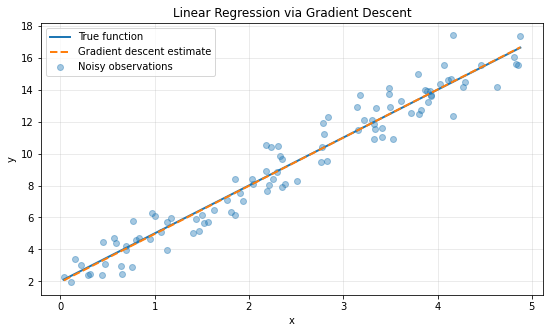

In [8]:
#Plotting the results

order = np.argsort(x)

plt.figure(figsize=(9, 5))

plt.scatter(x, y, alpha=0.4, label="Noisy observations")
plt.plot(x[order], y_true[order], label="True function", linewidth=2)
plt.plot(x[order], (X @ theta_hat)[order],
         "--", label="Gradient descent estimate", linewidth=2)

plt.xlabel("x")
plt.ylabel("y")
plt.title("Linear Regression via Gradient Descent")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

The above plot shows that our gradient descent estimate yields estimates that are close to the noisy observations and most importantly, the line induced by the gradient-descent estimate is close to the line induced by the data-generating function.